            Name            Team  Number Position  Age  Height  Weight  \
0  Avery Bradley  Boston Celtics       0       PG   25  06-Feb     180   
1    Jae Crowder  Boston Celtics      99       SF   25  06-Jun     235   
2   John Holland  Boston Celtics      30       SG   27  06-May     205   
3    R.J. Hunter  Boston Celtics      28       SG   22  06-May     185   
4  Jonas Jerebko  Boston Celtics       8       PF   29  06-Oct     231   

             College     Salary  
0              Texas  7730337.0  
1          Marquette  6796117.0  
2  Boston University        NaN  
3      Georgia State  1148640.0  
4                NaN  5000000.0  
Dataset Shape:  (458, 9)
Column Names:  Index(['Name', 'Team', 'Number', 'Position', 'Age', 'Height', 'Weight',
       'College', 'Salary'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 458 entries, 0 to 457
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      458 n

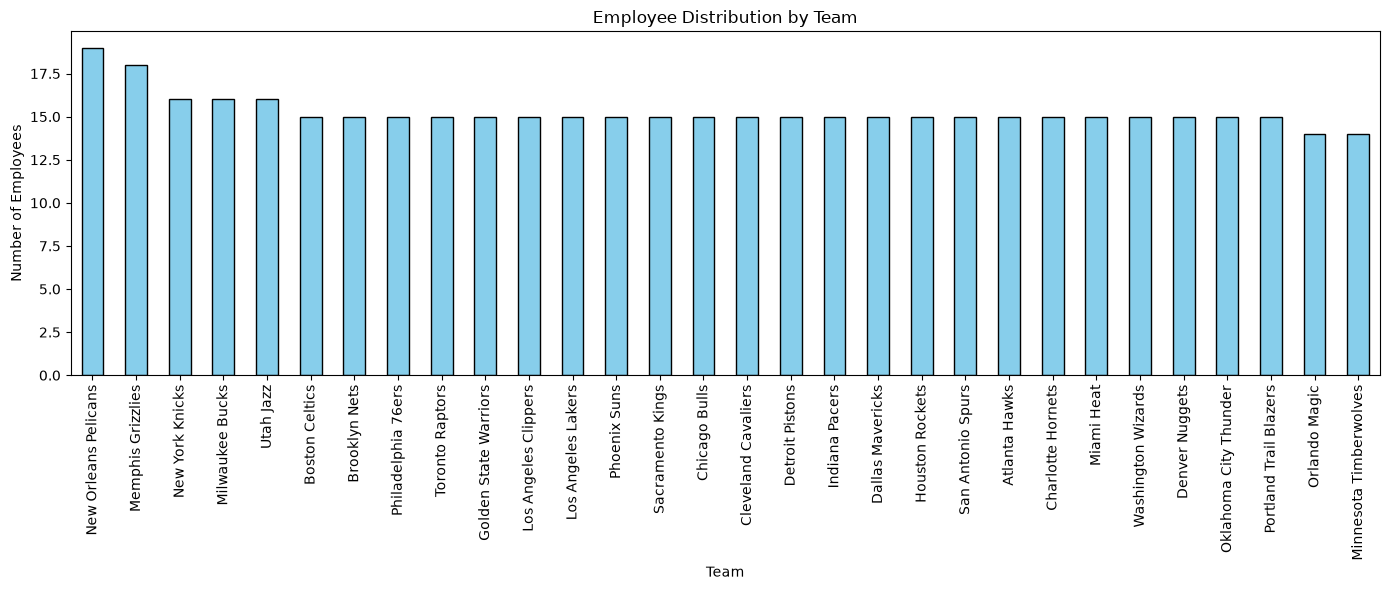

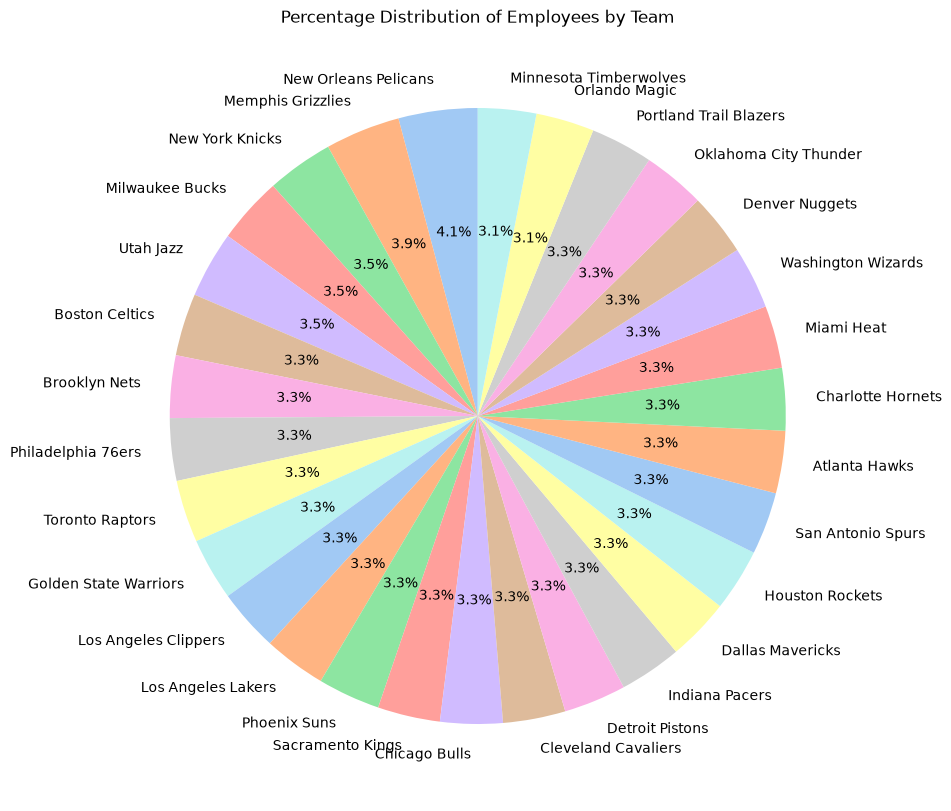

In [ ]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load the data
df = pd.read_csv('abc_company_employees.csv')

# Display the first few rows of the data
print(df.head())

# Check dataset shape
print("Dataset Shape: ", df.shape)

# Check column names
print("Column Names: ", df.columns)

# Dataset Information
print("Dataset Information: ", df.info())

# Check for missing values
print(df.isnull().sum())

# --------------------------------
# DATA PREPROCESSING
# --------------------------------

# Replace Height with random values
np.random.seed(42)
df['Height'] = np.random.randint(150,181, size=len(df))

# Display Updated Height Column
print(df[["Name", "Height"]].head(10))

# Verify minimum and maximum height
print("Minimum Height: ", df['Height'].min())
print("Maximum Height: ", df['Height'].max())

# Check dataset shapes
print("Updated Dataset Shape: ", df.shape)

# Save the preprocessed dataset
df.to_csv("preprocessed_abc_company_employees.csv", index=False)
print("Preprocessed dataset saved successfully")

# --------------------------------
# EMPLOYEE DISTRIBUTION BY TEAM
# --------------------------------

# Count of employees in each team
team_counts = df["Team"].value_counts()

print("\nEmployees in each team:")
print(team_counts)

# Calculate percentage of employees in each team
team_percentage = (team_counts / len(df)) * 100

print("\nPercentage Distribution : ")
print(team_percentage.round(2))

# Create a bar chart

plt.figure(figsize=(14,6))
team_counts.plot(kind="bar", color="skyblue", edgecolor="black")

plt.title("Employee Distribution by Team")
plt.xlabel("Team")
plt.ylabel("Number of Employees")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

# Create a pie chart

plt.figure(figsize=(10,10))
team_counts.plot(kind="pie", autopct='%1.1f%%', startangle=90, colors=sns.color_palette("pastel"))

plt.title("Percentage Distribution of Employees by Team")
plt.ylabel("")
plt.show()


Segregate employees based on their positions


Employees in each position:
Position
SG    102
PF    100
PG     92
SF     85
C      79
Name: count, dtype: int64

Position Percentage: 
Position
SG    22.27
PF    21.83
PG    20.09
SF    18.56
C     17.25
Name: count, dtype: float64


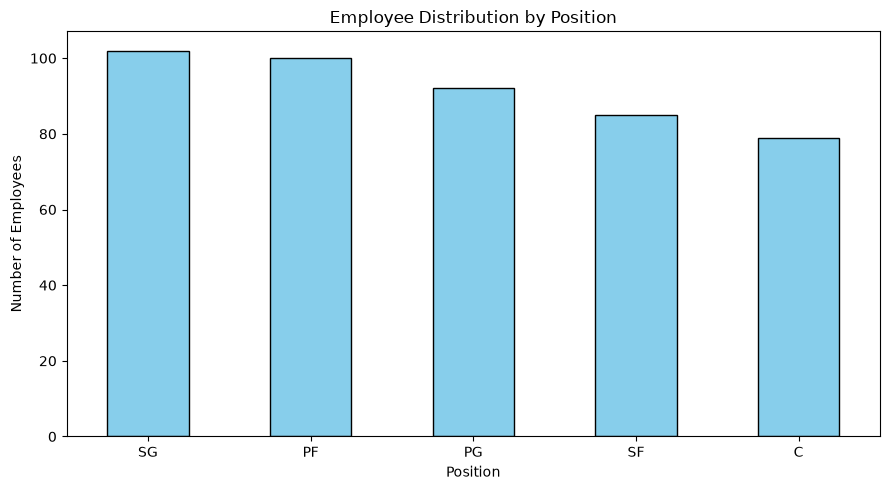

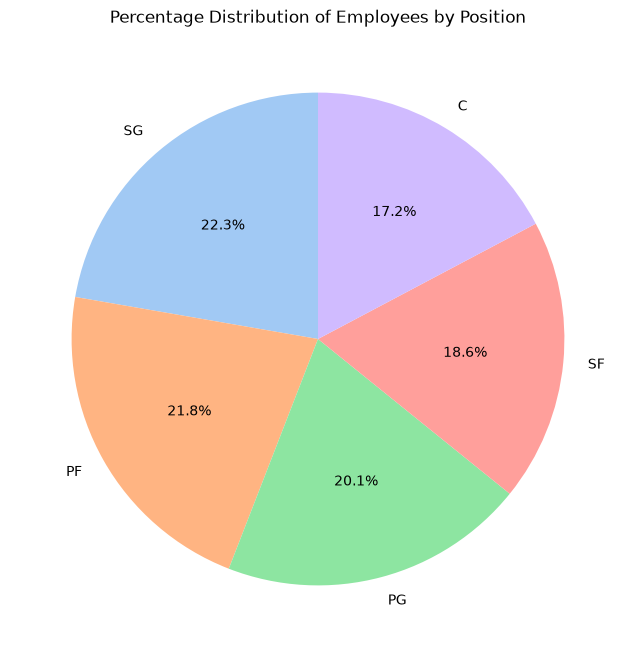

In [18]:
# --------------------------------
# EMPLOYEE DISTRIBUTION BY POSITION
# --------------------------------

position_counts = df["Position"].value_counts()

print("\nEmployees in each position:")
print(position_counts)

# Calculate percentage

position_percentage = (position_counts / len(df)) * 100

print("\nPosition Percentage: ")
print(position_percentage.round(2))

# Visualize using a bar chart

plt.figure(figsize=(9,5))

position_counts.plot(kind="bar", color="skyblue", edgecolor="black")

plt.title("Employee Distribution by Position")
plt.xlabel("Position")
plt.ylabel("Number of Employees")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Visualize using a pie chart

plt.figure(figsize=(8,8))
position_counts.plot(kind="pie", autopct='%1.1f%%', startangle=90, colors=sns.color_palette("pastel"))

plt.title("Percentage Distribution of Employees by Position")
plt.ylabel("")
plt.show()

Identify the predominant age group among employees


Employees in each age group:
Age Group
18-25    200
26-30    167
31-35     68
36-40     23
Name: count, dtype: int64

Age Group Percentage: 
Age Group
18-25    43.67
26-30    36.46
31-35    14.85
36-40     5.02
Name: count, dtype: float64

Predominant Age Group:  18-25
Number of Employees:  200


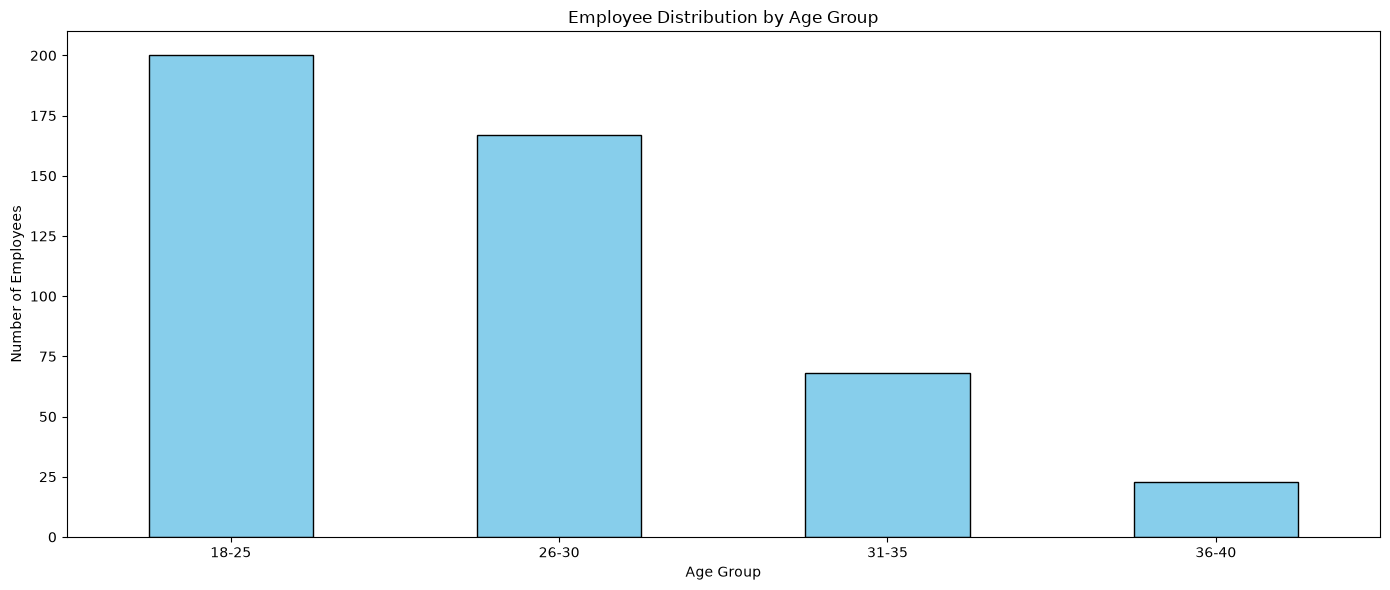

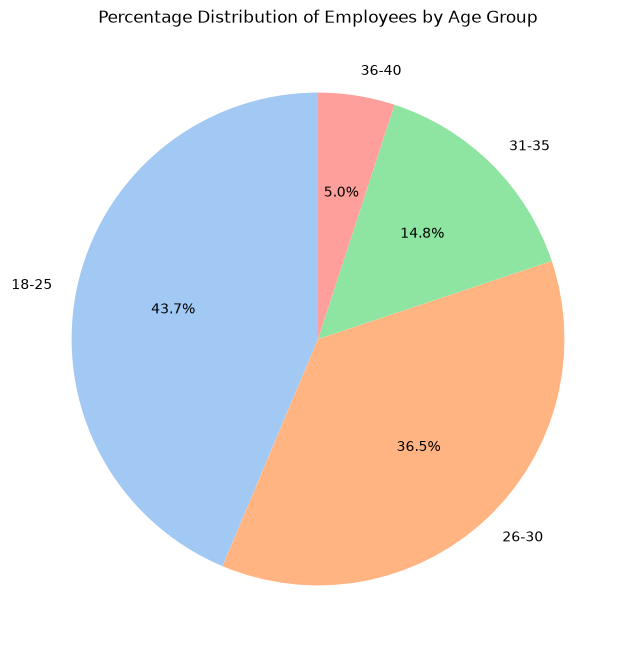

In [23]:
# --------------------------------
# AGE GROUP ANALYSIS
# --------------------------------

# Create age groups

bins = [18,25,30,35,40]
labels = ["18-25", "26-30", "31-35", "36-40"]

df["Age Group"] = pd.cut(df["Age"],bins=bins, labels=labels, include_lowest=True)

# Count of employees in each age group
age_group = df["Age Group"].value_counts().sort_index()

print("\nEmployees in each age group:")
print(age_group)

# Calculate percentage

age_percentage = (age_group / len(df)) * 100

print("\nAge Group Percentage: ")
print(age_percentage.round(2))

# Find the predominant age group
# Find the age group with maximum number of employees

predominant_age_group = age_group.idxmax()
print("\nPredominant Age Group: ", predominant_age_group)
print("Number of Employees: ", age_group.max())

# Visualize the predominant age group in a bar chart

plt.figure(figsize=(14,6))
age_group.plot(kind="bar", color="skyblue", edgecolor="black")

plt.title("Employee Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Visualize the predominant age group in a pie chart

plt.figure(figsize=(8,8))
age_group.plot(kind="pie", autopct='%1.1f%%', startangle=90, colors=sns.color_palette("pastel"))

plt.title("Percentage Distribution of Employees by Age Group")
plt.ylabel("")
plt.show()
